# Overview
This notebook identifies significant r values
* fisherZ correct
* stack across participants and runs
* run t-test and identify r values greater than 0
* reconvert fisherZ back to correlation coefficients
* stack coefficients across hemisphere for multiple comparisons
* save results in corresponding hemisphere while preserving medial/non-medial wall vertices

### modules

In [3]:
import numpy as np
import pandas as pd
import os, re
from os.path import join
import scipy.stats
from statsmodels.stats.multitest import multipletests
import nibabel as nib
from pathlib import Path


### function: write_gifti

In [2]:
def write_gifti_v2(data, output_fn, template_fn):
    gii = nib.load(template_fn)
    for i in np.arange(gii.numDA):
        gii.remove_gifti_data_array(0)
    gda = nib.gifti.GiftiDataArray(data)
    gii.add_gifti_data_array(gda)
    # nib.gifti.write(gii, output_fn)
    gii.to_filename(output_fn)

### parameters

In [4]:
suma_dir = '/dartfs/rc/lab/H/HaxbyLab/heejung/data/niml'# '/Users/h/suma-fsaverage6'
# main_dir = '/dartfs/rc/lab/D/DBIC/DBIC/f0042x1/life-encoding'
 #'/Volumes/life-encoding'
main_dir = '/dartfs/rc/lab/H/HaxbyLab/heejung/results/revision/glove/ws_pca-40'
results_dir = os.path.join(main_dir )#'results', 'himalaya', "glove")
alignment = 'ws' #'ha_common'
results = [ 'scenes-r', 'agents-r','actions-r', 'objects-r', 'moten-r']
runs = [1, 2, 3, 4]
hemis = ['lh', 'rh']
pca_comp = 40
fmri_durs = {1: 374, 2: 346, 3: 377, 4: 412}
n_samples = 1509
n_vertices = 40962
n_medial = {'lh': 3486, 'rh': 3491}
unique_keys = [
    re.search(r'sub-\d+', p.name).group()
    for p in Path(results_dir).glob('*.npy')
    if p.is_file() and re.search(f'sub-\d+', p.name)
]

# subjects = Path(result_dir).rglob('*sub-*.npy')
subjects = sorted(list(set(unique_keys)))
# subjects = ['sub-rid000001', 'sub-rid000005', 'sub-rid000006',
#             'sub-rid000009', 'sub-rid000012', 'sub-rid000014',
#             'sub-rid000017', 'sub-rid000019', 'sub-rid000024',
#             'sub-rid000027', 'sub-rid000031', 'sub-rid000032',
#             'sub-rid000033', 'sub-rid000034', 'sub-rid000036',
#             'sub-rid000037', 'sub-rid000038', 'sub-rid000041']



KeyboardInterrupt: 

# compute one sample t-tests (only run once!)

In [5]:
for result in results:
    hemi_t = []
    hemi_p = []
    hemi_mean = []
    output_dir = os.path.join(results_dir,result) #, # f'{alignment}_pca-40')
    print(f"starting {result} ________________")
    for hemisphere in hemis:
        medial_mask = np.load(os.path.join(suma_dir, f'fsaverage6_medial_{hemisphere}.npy'))
        assert np.sum(medial_mask) == n_medial[hemisphere]
        cortical_vertices = ~medial_mask # boolean (true for non-medials, false for medials)
        cortical_coords = np.where(cortical_vertices)[0] # returns indices of non-medials
        avg_all = []
        # NOTE 1. Fisher z transform per run per participant (np.arctanh)
        for test_subject in subjects:
            stack_fisherz_run = []
            for test_run in runs:           
                try: 
                    split_fname = f"{output_dir}/{result}_pca-{pca_comp}_align-{alignment}_{test_subject}_run-{test_run}_hemi-{hemisphere}.npy"
                    run_data = np.load(split_fname)
                except (FileNotFoundError) as e:
                    print(f"missing file: {split_fname}")
                    continue
                fisherz_run = np.arctanh(run_data) #[0, cortical_coords]) #cortical_vertices])
                stack_fisherz_run.append(fisherz_run.flatten())
        
            if len(stack_fisherz_run) == 0:
                print(f"  -> skipping {test_subject} for {hemisphere}: no valid runs found")
                continue

            # NOTE: 2. average (z-transformed) correlations across runs: yields 18 maps (1 per subject)
            avg_run = np.mean(np.vstack(stack_fisherz_run), axis = 0)
            avg_all.append(avg_run)

        if len(avg_all) == 0:
            print(f"  -> WARNING: no subjects with valid data for {result}, {hemisphere}. Skipping.")
            continue
        fisherz_all = np.vstack(avg_all) # 18 x nonmedial (per hemi)

        # NOTE: 3. Scipy ttest_1samp to get t-value and p-value
        t, p = scipy.stats.ttest_1samp(fisherz_all, popmean=0,axis=0, alternative='greater')
        hemi_t.append(t)
        hemi_p.append(p)
        hemi_mean.append(np.tanh(np.nanmean(fisherz_all, axis = 0)))

    # %% NOTE: 4-1. concatenate (np.hstack) the two hemispheres p-values (and exclude medial wall) prior to computing FDR (load in cortical_vertices.npy)
    left_vert = hemi_p[0].shape[0]
    t_all = np.hstack(hemi_t)
    p_all = np.hstack(hemi_p)

    reject, q_all, _, _ = multipletests(p_all, method = 'fdr_bh')
    q_both = [q_all[:left_vert], q_all[left_vert:]]
    print("* completed t-tests for both hemispheres")
    hemilabels = ['lh', 'rh']
    Path(join(output_dir, 'stats')).mkdir(parents = True, exist_ok = True)
    for h, hemisphere in enumerate(hemis):
        stats = np.zeros((n_vertices))
        hemi_mean[h][q_both[h] >= .05] = 0
        medial_mask = np.load(os.path.join(suma_dir, f'fsaverage6_medial_{hemisphere}.npy'))
        assert np.sum(medial_mask) == n_medial[hemisphere]
        cortical_vertices = ~medial_mask # boolean (true for non-medials, false for medials)
        cortical_coords = np.where(cortical_vertices)[0] # returns indices of non-medials
        stats[cortical_coords] = hemi_mean[h]
        save_fname = f"{output_dir}/stats/{result}_pca-{pca_comp}_align-{alignment}_hemi-{hemisphere}_ttest.gii"
        write_gifti_v2(stats.astype(np.float32),
        template_fn = os.path.join(suma_dir, f"{hemilabels[h]}.pial.gii"), 
        output_fn = save_fname)
    print("* saved output (thresholded average r) for both hemispheres")


starting actions-r ________________
* completed t-tests for both hemispheres
* saved output (thresholded average r) for both hemispheres
starting moten-r ________________
* completed t-tests for both hemispheres
* saved output (thresholded average r) for both hemispheres


# Run locally

# plot results in fslr

plot t-test results in surfplots, Freesurfer surface plots

In [6]:
from neuromaps.datasets import fetch_fsaverage, fetch_fslr
import numpy as np
from surfplot import Plot
import nibabel as nib
import matplotlib.pyplot as plt
from matplotlib import colors
from os.path import join
import nibabel as nib
surfaces = fetch_fsaverage()
lh, rh = surfaces['inflated']
# main_dir = '/Volumes/life-encoding'
main_dir = '/Volumes/ws_pca-40'

alignment = 'ws'

In [46]:
def fsaverage_to_fslr_and_plot(Lfname, Rfname, key, cmap='inferno', max=.20):
    from neuromaps.datasets import fetch_fslr
    from neuromaps.transforms import fsaverage_to_fslr
    giiL = nib.load(Lfname)
    giiR = nib.load(Rfname)
    L_fslr = fsaverage_to_fslr(giiL, target_density='32k', hemi='L', method='linear')
    R_fslr = fsaverage_to_fslr(giiR, target_density='32k', hemi='R', method='linear')
    
    surfaces_fslr = fetch_fslr()
    lh_fslr, rh_fslr = surfaces_fslr['inflated']

    color_range = (0,0.1) #max)
    p = Plot(surf_lh=lh_fslr, 
             surf_rh=rh_fslr, 
             size=(1000, 200), 
             zoom=1.2, layout='row', 
             views=['lateral', 'medial', 'ventral', 'posterior'], 
             mirror_views=True, brightness=.7)
    p.add_layer({'left': L_fslr[0], 
                'right': R_fslr[0]}, 
                cmap=cmap, cbar=True,
                color_range=color_range,
                cbar_label=key
                ) # YlOrRd_r
    cbar_kws = dict(outer_labels_only=True, pad=.02, n_ticks=2, decimals=3)
    fig = p.build(cbar_kws=cbar_kws)
    # fig.show()
    return(fig)


In [47]:
import os
import shutil
from neuromaps import datasets

# 1. Force delete the entire atlas directory
atlas_path = '/Users/h/neuromaps-data/atlases/fsaverage'
if os.path.exists(atlas_path):
    print(f"Removing corrupted directory: {atlas_path}")
    shutil.rmtree(atlas_path)

# 2. Re-download
print("Attempting fresh download...")
datasets.fetch_atlas('fsaverage', density='41k')

# 3. Inspect the file content immediately
target_file = os.path.join(atlas_path, 'tpl-fsaverage_den-41k_hemi-L_sphere.surf.gii')

if os.path.exists(target_file):
    with open(target_file, 'r', errors='ignore') as f:
        first_line = f.readline()
        print(f"\nFile Header Check: {first_line[:50]}")
        
        if "<?xml" in first_line:
            print("✅ SUCCESS: Found valid XML header.")
        elif "<!DOCTYPE html" in first_line or "<html" in first_line:
            print("❌ FAILURE: Downloaded an HTML error page instead of data.")
        else:
            print("❌ FAILURE: Unknown file format or empty file.")

Removing corrupted directory: /Users/h/neuromaps-data/atlases/fsaverage
Attempting fresh download...

File Header Check: <?xml version="1.0" encoding="UTF-8"?>

✅ SUCCESS: Found valid XML header.


 ...done. (2 seconds, 0 min)
Extracting data from /Users/h/neuromaps-data/9e29c30a00cc86995f334ba48854d362/fsaverage41k.tar.gz..... done.


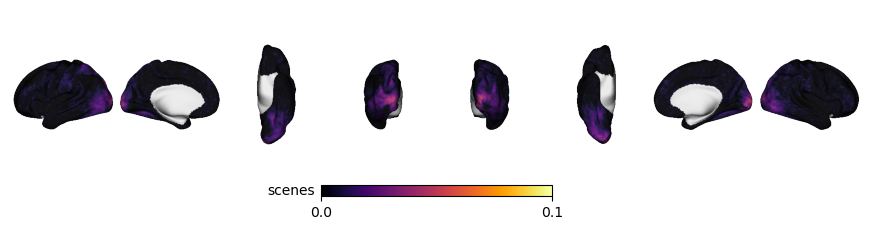

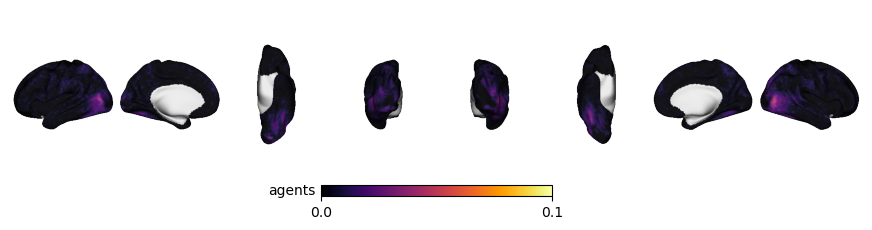

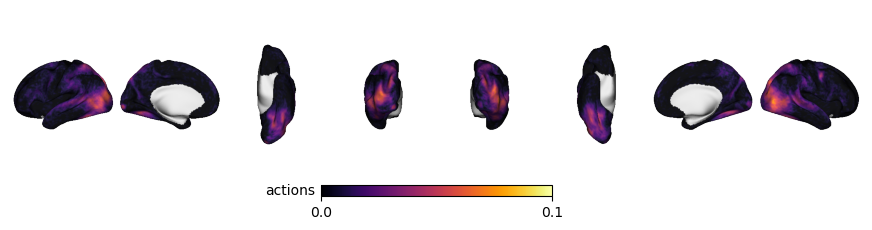

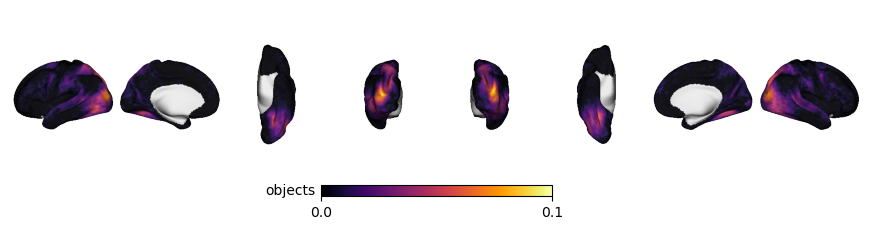

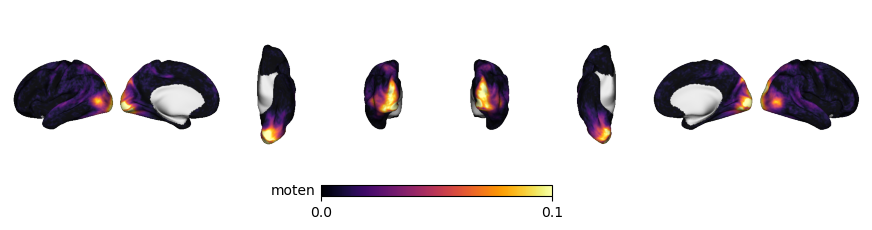

In [48]:
alignment = 'ws'
save_dir = '/Users/h/Documents/projects_local/life-encoding/figure/revision'
# ['bg', 'agents', 'actions', 'moten']
for feature in ['scenes', 'agents', 'actions', 'objects', 'moten']:
    output_dir = os.path.join(results_dir,f"{feature}-r")
    gii_dir = join(output_dir, 'stats')

    bgLfname = f"{gii_dir}/{feature}-r_pca-40_align-{alignment}_hemi-lh_ttest.gii"
    bgRfname = f"{gii_dir}/{feature}-r_pca-40_align-{alignment}_hemi-rh_ttest.gii"
    
    fig = fsaverage_to_fslr_and_plot(bgLfname, bgRfname, feature, cmap='inferno', max=.2)
 
    fig.savefig(join(save_dir, f"{feature}-r_pca-40_align-{alignment}_hemi-lh_ttest.png"), dpi=300)

## count significant voxels
How many voxels are significant per stat map (FDR-corrected)?

In [49]:
results_dir

'/Volumes/ws_pca-40'

In [50]:
alignment = 'ws'
# ['bg', 'agents', 'actions', 'moten']
for feature in ['scenes', 'agents', 'actions', 'objects', 'moten']:
# feature = 'bg'
    output_dir = os.path.join(results_dir,f"{feature}-r")
    gii_dir = join(output_dir, 'stats')
    Lfname = f"{gii_dir}/{feature}-r_pca-40_align-{alignment}_hemi-lh_ttest.gii"
    Rfname = f"{gii_dir}/{feature}-r_pca-40_align-{alignment}_hemi-rh_ttest.gii"
    # fsaverage_to_fslr_and_plot(bgLfname, bgRfname, feature, cmap='inferno', max=.2)

    giiL = nib.load(Lfname)
    giiR = nib.load(Rfname)

    sig_voxel = np.sum(giiL.agg_data() > 0) + np.sum(giiR.agg_data() > 0) 
    print(f"{feature}: {sig_voxel}")


scenes: 51884
agents: 53646
actions: 59879
objects: 56657
moten: 62417


# cluster thresholded

We threshold the maps using work bench. The output is a (semi) boolean mask, thereby, we apply the mask back onto the t-test maps. 
Steps include
* Workbench cluster threshold
* multiply workbench mask with t-test maps
* plot thresholded maps

### workbench cluster threshold

In [58]:
from subprocess import call
# parameteres
hemis = ['lh', 'rh']
features = ['scenes', 'agents', 'actions', 'objects', 'moten']
clustersize = 200
hemi_dict = {'lh': 'L', 'rh': 'R'}
fsaverage_dir = '/Users/h/neuromaps-data/atlases/fsaverage'


# thresholding via workbench
for hemi in hemis:
    for feature in features:
        output_dir = os.path.join(results_dir,f"{feature}-r")
        gii_dir = join(output_dir, 'stats')
        fsaverage_template = f"{fsaverage_dir}/tpl-fsaverage_den-41k_hemi-{hemi_dict[hemi]}_inflated.surf.gii"
        himalaya = f"{gii_dir}/{feature}-r_pca-40_align-ws_hemi-{hemi}_ttest.gii"
        outputfname = f"{gii_dir}/{feature}-r_pca-40_align-ws_hemi-{hemi}_ttest_cluster-{clustersize}.gii"
        return_code = call(f"wb_command -metric-find-clusters {fsaverage_template} {himalaya} 0 {clustersize} {outputfname}", shell=True)
print(f"Return: {return_code}")

Return: 0


## check cluster maps
The images will look like masks

In [59]:
alignment

'ws'

Context leak detected, msgtracer returned -1


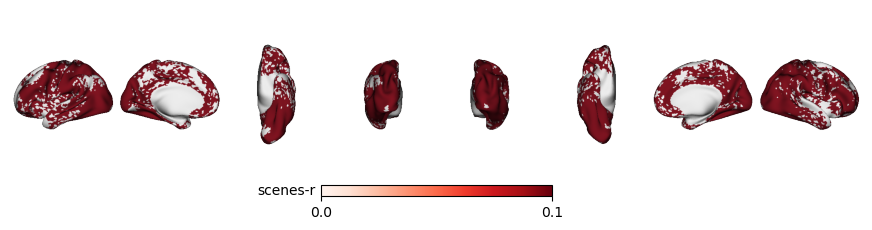

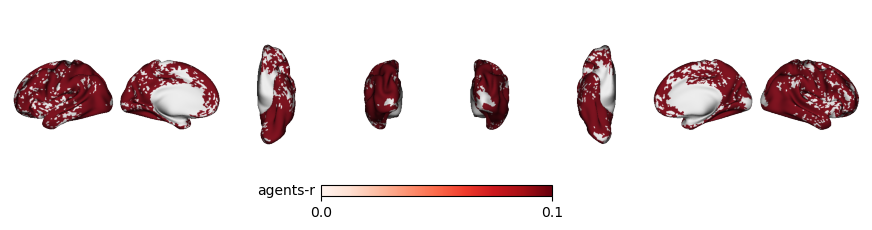

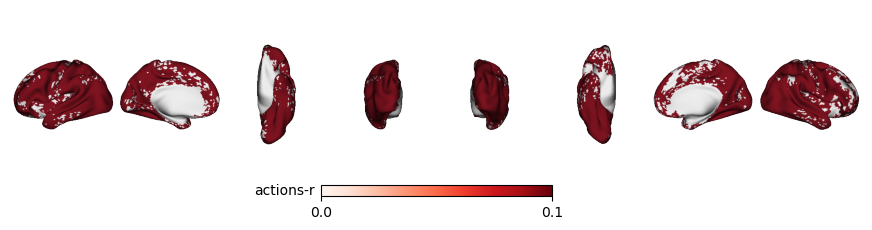

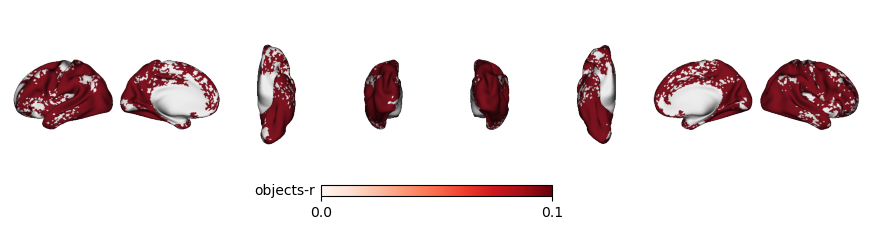

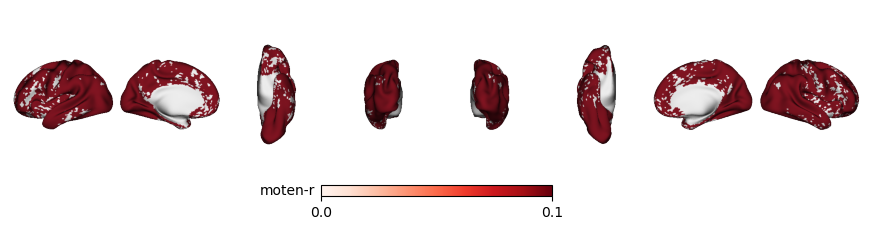

In [60]:
for feature in ['scenes', 'agents', 'actions', 'objects', 'moten']:
    output_dir = os.path.join(results_dir,f"{feature}-r")
    gii_dir = join(output_dir, 'stats')
    clusterthresL = f"{gii_dir}/{feature}-r_pca-40_align-{alignment}_hemi-lh_ttest_cluster-{clustersize}.gii"
    clusterthresR = f"{gii_dir}/{feature}-r_pca-40_align-{alignment}_hemi-rh_ttest_cluster-{clustersize}.gii"
    fsaverage_to_fslr_and_plot(clusterthresL, clusterthresR, f'{feature}-r', cmap = 'Reds')

## multiply workbench cluster threshold maps to t-test maps

In [61]:
clustersize

200

In [62]:
def write_gifti_v2(data, output_fn, template_fn):
    gii = nib.load(template_fn)
    for i in np.arange(gii.numDA):
        gii.remove_gifti_data_array(0)
    gda = nib.gifti.GiftiDataArray(data)
    gii.add_gifti_data_array(gda)
    # nib.gifti.write(gii, output_fn)
    gii.to_filename(output_fn)

hemis = ['lh', 'rh']
hemi_dict = {'lh': 'L', 'rh': 'R'}
features = ['scenes', 'agents', 'actions', 'objects', 'moten']
# clustersize = 50

fsaverage_dir = '/Users/h/neuromaps-data/atlases/fsaverage'

# thresholding via workbench
for hemi in hemis:
    for feature in features:
        output_dir = os.path.join(results_dir,f"{feature}-r")
        gii_dir = join(output_dir, 'stats')
        clustermask_fname = f"{gii_dir}/{feature}-r_pca-40_align-{alignment}_hemi-{hemi}_ttest_cluster-{clustersize}.gii"
        clustL = nib.load(clustermask_fname).agg_data() > 0
        himalaya_fname = f"{gii_dir}/{feature}-r_pca-40_align-{alignment}_hemi-{hemi}_ttest.gii"
        himalaya = nib.load(himalaya_fname).agg_data()
        maskeddata = clustL * himalaya
        write_gifti_v2(maskeddata.astype(np.float32), 
            output_fn=f"{gii_dir}/{feature}-r_pca-40_align-{alignment}_hemi-{hemi}_ttest_thres-cluster{clustersize}.gii",
            template_fn=f"{fsaverage_dir}/tpl-fsaverage_den-41k_hemi-{hemi_dict[hemi]}_pial.surf.gii")

## plot thresholded maps in fslr [manuscript]

In [63]:
main_dir

'/Volumes/ws_pca-40'

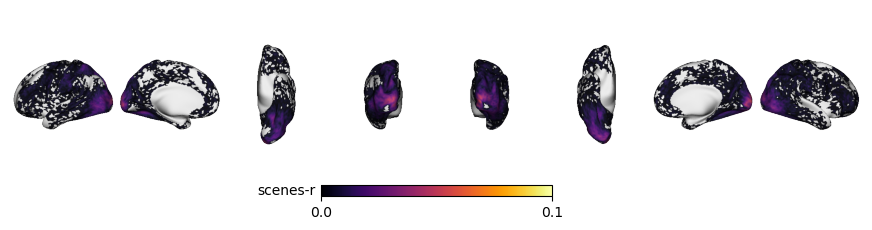

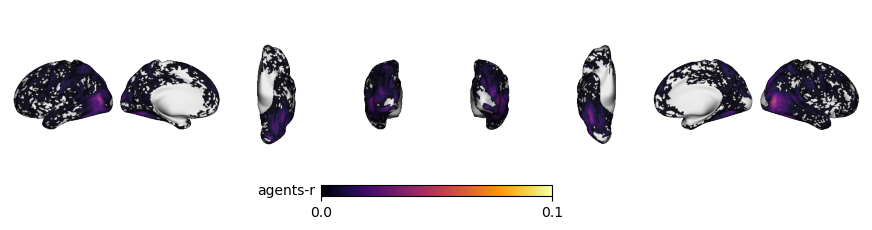

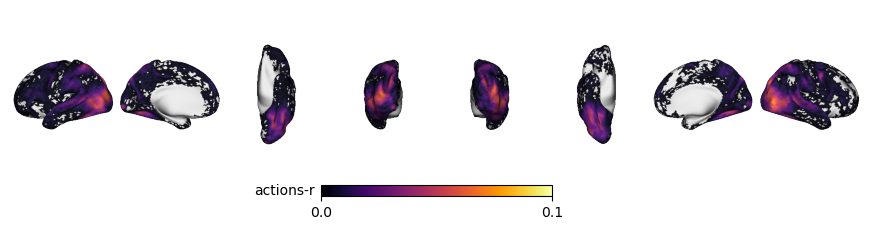

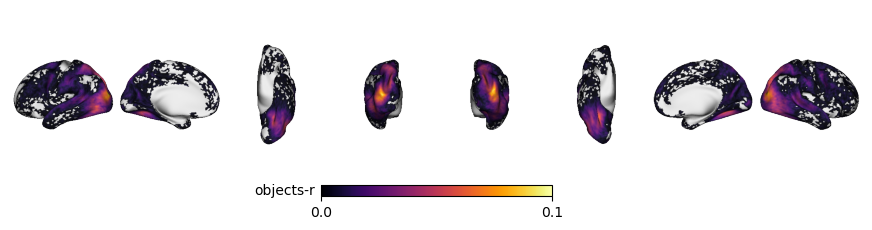

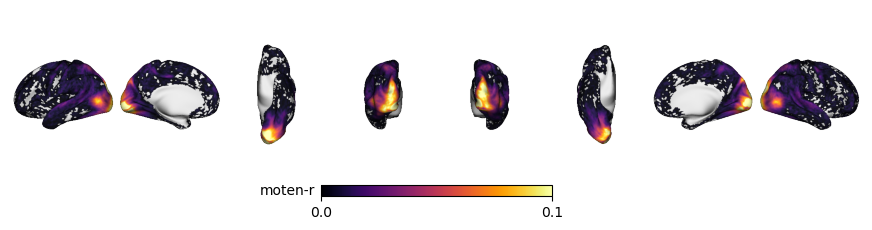

In [64]:
save_dir = '/Users/h/Documents/projects_local/life-encoding/figure/revision'
Path(save_dir).mkdir(parents=True, exist_ok=True)
for feature in['scenes', 'agents', 'actions', 'objects', 'moten']:
    output_dir = os.path.join(results_dir,f"{feature}-r")
    gii_dir = join(output_dir, 'stats')
    thresL = f"{gii_dir}/{feature}-r_pca-40_align-{alignment}_hemi-lh_ttest_thres-cluster{clustersize}.gii"
    thresR = f"{gii_dir}/{feature}-r_pca-40_align-{alignment}_hemi-rh_ttest_thres-cluster{clustersize}.gii"
    fig = fsaverage_to_fslr_and_plot(thresL, thresR, f'{feature}-r', cmap = 'inferno', max=.2)
    fig.savefig(join(save_dir, f"{feature}-r_pca-40_align-{alignment}_hemi-lh_ttest_thres-cluster{clustersize}.png"), dpi=300)